## 1 Consider the Cork Stoppers Data Set
• Find the two most significant features according to the KruskallWallis filter method


In [15]:
import pandas as pd
import numpy as np
from scipy import stats

df = pd.read_excel('D:/UC_library/Mestrado/1_ANO/2_semestre/RP/PL/data_sets/CORK_STOPPERS.XLS', sheet_name='Data')
df = df.dropna()

features = ["ART", "N.1", "PRT", "ARM", "PRM", "ARTG", "NG", "PRTG", "RAAR", "RAN"]
H = {feature : None for feature in features}

# kruskal wallis test 
for i in features:
    Super = df.loc[df["C"] == 1, i].values
    Average = df.loc[df["C"] == 2, i].values
    Poor = df.loc[df["C"] == 3, i].values

    H[i] =  stats.kruskal(Super, Average, Poor).statistic
   
sort_H = sorted(H.items(), key= lambda x:x[1], reverse=True)
for key,value in sort_H:
    print(key , ':' , value)

ART : 121.58964258474009
PRM : 117.63782046335828
PRT : 115.74851860346449
ARTG : 115.21685092055695
ARM : 113.53079541575394
PRTG : 113.33179317347778
RAAR : 105.18901177731905
NG : 104.41349241044973
RAN : 94.28568910767306
N.1 : 74.49926324214721


#### Two most significant features are: 'ART', 'PRM'


### Build two datasets using the Hold-Out method. Consider 50% of the patterns for training and 50% for testing

In [37]:
from sklearn.model_selection import train_test_split


dataset = pd.DataFrame(df, columns=['ART', 'PRM', 'C'])
dataset = dataset.to_numpy()
x = dataset[:,[0,1]]
y = dataset[:, 2]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.5, random_state=1)


### Standardize the data to have zero mean and unit variance. Pay attention that standardization factors should be obtained only in the training data.

In [38]:
x_train_norm = (x_train - np.mean(x_train, axis=0)) / np.std(x_train, axis=0)
x_test_norm = (x_test - np.mean(x_train, axis=0)) / np.std(x_train, axis=0)

### Perform a K-NN classification of the data in order to discriminate between classes ω1, ω2 and ω3. Consider k=1 and k=7. Plot the decision boundaries and the testing errors.

Classification report for kNN (k = 1):
               precision    recall  f1-score   support

       Super       0.82      0.75      0.78        24
     Average       0.69      0.75      0.72        24
        Poor       0.93      0.93      0.93        27

    accuracy                           0.81        75
   macro avg       0.81      0.81      0.81        75
weighted avg       0.82      0.81      0.81        75
 

Classification report for kNN (k = 7):
               precision    recall  f1-score   support

       Super       0.83      0.83      0.83        24
     Average       0.71      0.83      0.77        24
        Poor       1.00      0.85      0.92        27

    accuracy                           0.84        75
   macro avg       0.85      0.84      0.84        75
weighted avg       0.86      0.84      0.84        75



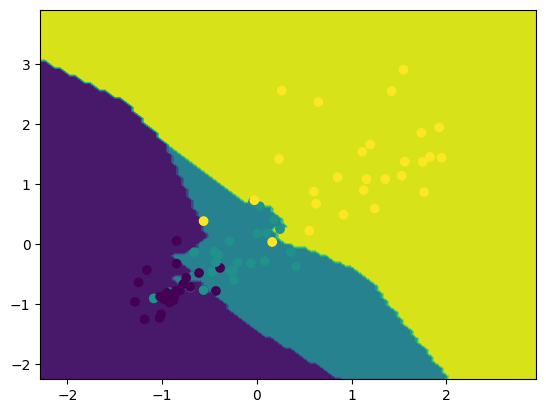

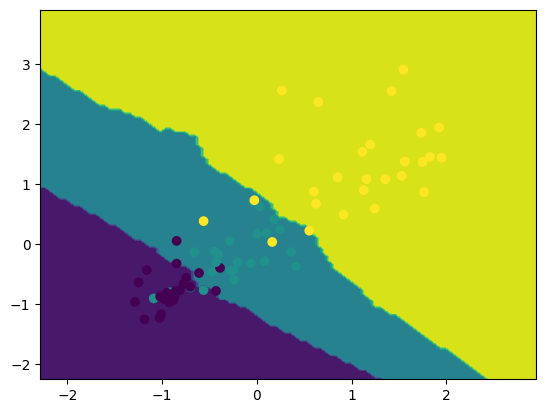

In [39]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import classification_report

knn1 = KNeighborsClassifier(n_neighbors=1)
knn7 = KNeighborsClassifier(n_neighbors=7)

# For k = 1
knn1.fit(x_train_norm, y_train)
predictions_knn1 = knn1.predict(x_test_norm)

# For k = 7
knn7.fit(x_train_norm, y_train)
predictions_knn7 = knn7.predict(x_test_norm)


print('Classification report for kNN (k = 1):\n',classification_report(y_test, predictions_knn1, target_names=['Super', 'Average', 'Poor']), '\n')
print('Classification report for kNN (k = 7):\n',classification_report(y_test, predictions_knn7, target_names=['Super', 'Average', 'Poor']))

display1 = DecisionBoundaryDisplay.from_estimator(knn1, x_test_norm, response_method= 'predict')
display1.ax_.scatter(x = x_test_norm[:,0], y = x_test_norm[:,1], c = y_test)


display7 = DecisionBoundaryDisplay.from_estimator(knn7, x_test_norm, response_method= 'predict')
display7.ax_.scatter(x = x_test_norm[:,0], y = x_test_norm[:,1], c = y_test)



### Develop a schema to find the appropriate number of neighbors. Plot the decision boundaries and the testing error for the better solution. Note: A robust estimation implies the reporting of statistical measures that account for bias and variability, such as mean and variance

In [55]:
import plotly.express as px

runs = np.arange(1,30,1)
ks = np.arange(1,30,1)

errMAT = np.zeros((runs.shape[0], ks.shape[0]))

for i in runs:
    x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.5, random_state=i)
    x_train_norm = (x_train - np.mean(x_train, axis=0)) / np.std(x_train, axis=0)
    x_test_norm = (x_test - np.mean(x_train, axis=0)) / np.std(x_train, axis=0)

    for k in ks:
        knn = KNeighborsClassifier(n_neighbors=k)
        knn.fit(x_train_norm, y_train)
        predictions = knn.predict(x_test_norm)

        acc = np.sum(y_test == predictions) / len(y_test) # accuracy
        err = 1-acc # 
        
        errMAT[i-1, k-1] = err

errMean = np.mean(errMAT, axis=0)
errSTD = np.std(errMAT, axis=0)

fig = px.scatter(x = ks, y = errMean, error_y=errSTD)
fig.show()

print('The optimal number of neighbours to use is k =',ks[np.argmin(errMean)])



The optimal number of neighbours to use is k = 13
